In [1]:
# %cd C:\Users\paull\Science\PhD\2022_deep_music\maestro_analysis
%cd D:\2022_deep_music\maestro_analysis

D:\2022_deep_music\maestro_analysis


In [2]:
import mne
mne.set_log_level(verbose=False)
mne.utils.set_config('MNE_USE_CUDA', 'true')
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import pickle
import copy
from maestro_analysis.utils import plot_seeg, plot_seeg_gridspec

In [3]:
#load epochs from files
path = 'F:/2022_deep_music/seeg/'
fs_path = path + 'freesurfer/'
evoked_path = path + 'evoked/'
save_path = evoked_path

with open(evoked_path + 'evoked_data.pkl', 'rb') as handle:
    evoked_data = pickle.load(handle)

In [4]:
#extract data/montages from epochs
sub_list = list(evoked_data.keys())
epochs_tw = evoked_data[sub_list[0]]['epochs_tw']
baseline_tw = evoked_data[sub_list[0]]['baseline_tw']
times = evoked_data[sub_list[0]]['epochs'].times
data = []
montages = []
for sub in sub_list:
    data.append(evoked_data[sub]['epochs'].get_data())
    # print('N channels in data :', evoked_data[sub]['epochs'].get_data().shape[1])
    montages.append(evoked_data[sub]['epochs'].get_montage())
    # print('N channels in montage :', len(evoked_data[sub]['epochs'].get_montage().ch_names))

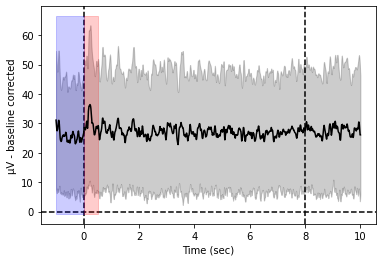

Baseline mean, std =  25.653010838915087 7.130601176151406
Response mean, std =  30.132046712616567 9.130055360760661
Response score_mean = 4.479035873701477
Response score_std = 1.172570708750145
Response score_z = 25.6974240340138


In [38]:
#plot exemplar channels
sub = 'Tou_Et'
i_sub = sub_list.index(sub)
ch = "H'7" #H'7, H'8, Ia'5, Ia'10
ch_names = evoked_data[sub]['epochs'].ch_names
i_ch = ch_names.index(ch)
tw = [0, 0.5]
tw_lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()+1]
baseline_tw_lim = [np.abs(times - baseline_tw[0]).argmin(), np.abs(times - baseline_tw[1]).argmin()+1]

data_ch = np.abs(copy.copy(data[i_sub][:,i_ch,:])) * 1e6
y = np.mean(data_ch,axis=0)
y_std = np.std(data_ch,axis=0)
fig,ax = plt.subplots()
ax.plot(times, y, color = 'k')
ax.fill_between(times, y-y_std, y+y_std,alpha=0.2, color = 'k') #tw
# ax.plot(times, np.abs(y), color = 'grey')
ylim = ax.get_ylim()
ax.fill_between(times[baseline_tw_lim[0]:baseline_tw_lim[1]], ylim[0], ylim[1],alpha=0.2, color = 'b') #baseline
ax.fill_between(times[tw_lim[0]:tw_lim[1]], ylim[0], ylim[1],alpha=0.2, color = 'r') #tw
ax.axvline(0, linestyle='--', color='k', zorder=0)
ax.axvline(8, linestyle='--', color='k', zorder=0)
ax.axhline(0, linestyle='--', color='k', zorder=0)
ax.set_ylabel('µV - baseline corrected')
ax.set_xlabel('Time (sec)')
plt.show()

# response = np.abs(data_ch[:,tw_lim[0]:tw_lim[1]])
# baseline = np.abs(data_ch[:,baseline_tw_lim[0]:baseline_tw_lim[1]]) #baseline mean has already been substracted from the stim period
response = np.abs(data_ch[:,tw_lim[0]:tw_lim[1]])
baseline = np.abs(data_ch[:,baseline_tw_lim[0]:baseline_tw_lim[1]])
m_resp = np.mean(response, axis= 1) #average over time
m_base = np.mean(baseline, axis = 1) #average over time
s_std = np.std(response,axis=(0,1)) / np.std(baseline,axis=(0,1))
s_mean = np.mean(response,axis=(0,1)) - np.mean(baseline,axis=(0,1))
s_z = np.mean(response,axis=(0,1)) * (np.std(baseline,axis=(0,1)) / np.std(response,axis=(0,1)))
print('Baseline mean, std = ', np.mean(m_base), np.std(m_base))
print('Response mean, std = ', np.mean(m_resp), np.std(m_resp))
print('Response score_mean =', s_mean)
print('Response score_std =', s_std)
print('Response score_z =', s_z)

-- Bou_Al
[(2.131663410310337, "TP'1"), (2.602073356116637, "TP'2"), (2.5079389019163347, "TP'3"), (2.6696412288239793, "TP'4"), (2.6434669756749547, "TP'5"), (2.6374459771699947, "TP'6"), (2.67666354653056, "TP'7"), (2.364052823399802, "TP'8"), (2.7609504228040995, "TP'9"), (3.011111862294625, "A'1"), (3.459975258985832, "A'2"), (3.35066614308213, "A'3"), (2.553755572517375, "A'4"), (2.5296594031031128, "A'5"), (2.603566227960921, "A'6"), (1.974376875884475, "A'9"), (1.7504058015763535, "A'10"), (1.5983914987127816, "A'11"), (1.600707397648437, "A'12"), (1.6276790925401126, "A'13"), (2.3907317063052873, "TB'1"), (2.3102643083474614, "TB'2"), (2.6838526775503992, "TB'3"), (2.428619972661009, "TB'4"), (2.361840847218164, "TB'5"), (2.033495227736983, "TB'6"), (2.0124245071263425, "TB'7"), (2.080045685021774, "TB'8"), (2.0762210350390973, "TB'9"), (1.8305906430229715, "TB'10"), (2.2981867898031254, "TB'11"), (2.818676464795968, "B'1"), (2.193255643778241, "B'2"), (2.588860614858198, "B'3"

D:\2022_deep_music\maestro_analysis\maestro_analysis\utils.py:579: RuntimeWarning: This filename (F:\2022_deep_music\seeg\epochs_note_level\Bou_Al_epochs_mono_preprocessed_IDA.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(sub_epochs_path,preload=False)
c:\ProgramData\Anaconda3\lib\site-packages\mne\viz\backends\_utils.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(default_colormap)
c:\ProgramData\Anaconda3\lib\site-packages\mne\viz\backends\_utils.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_

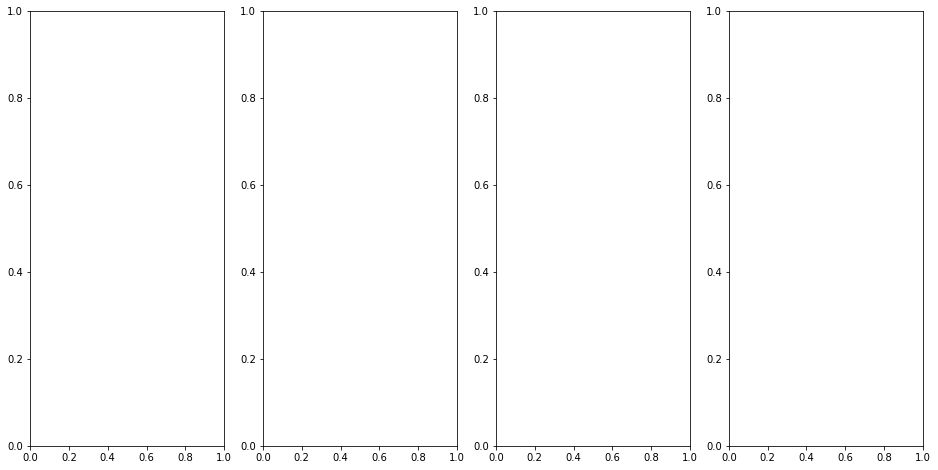

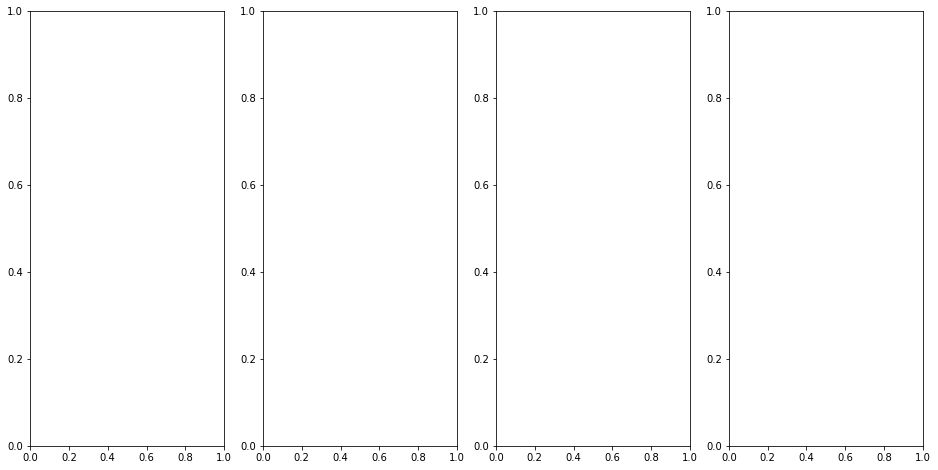

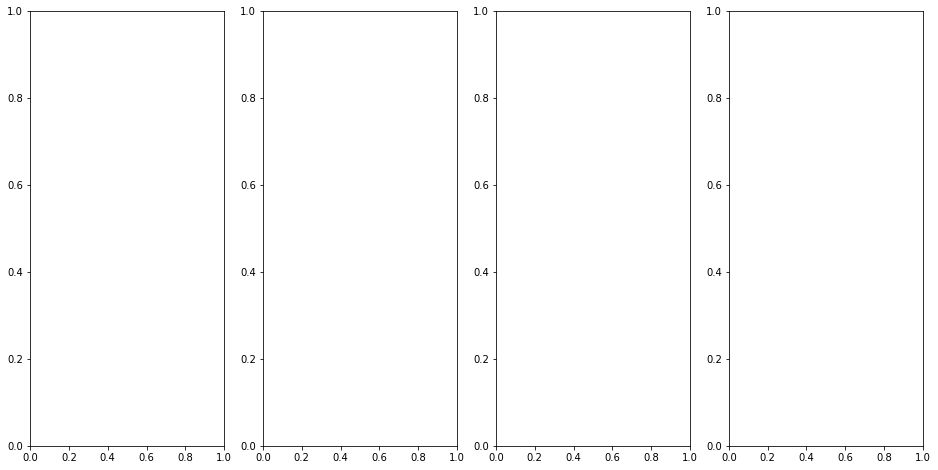

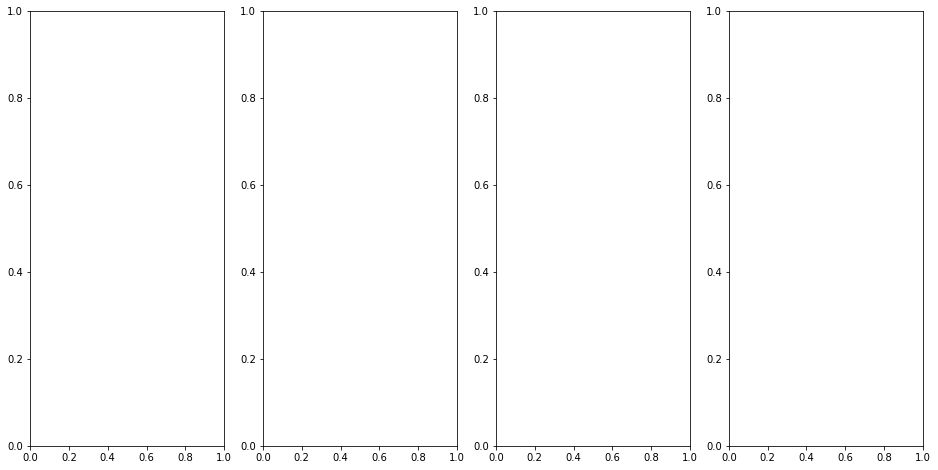

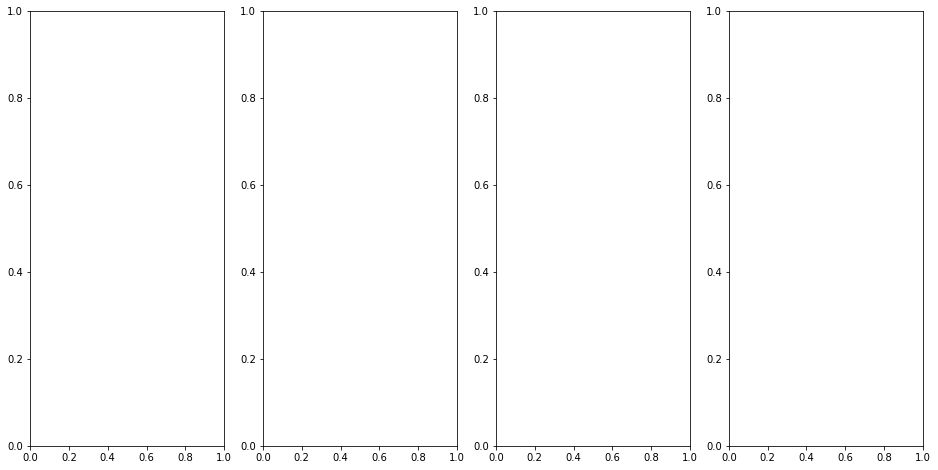

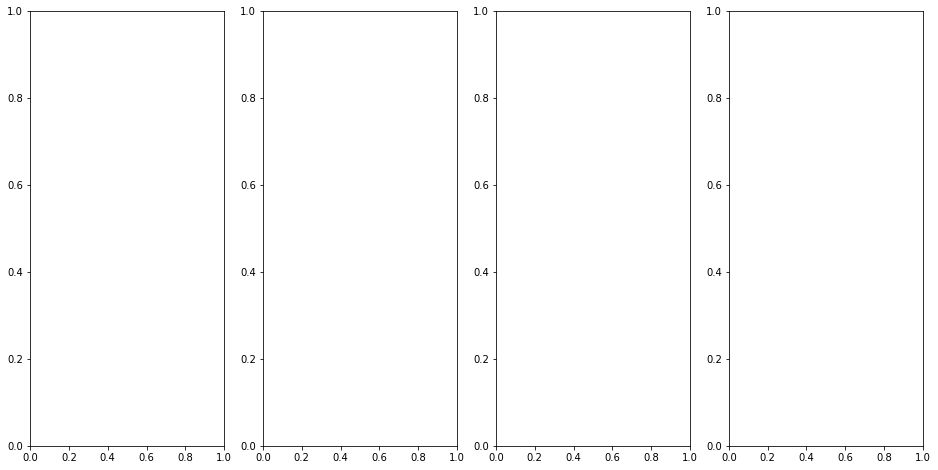

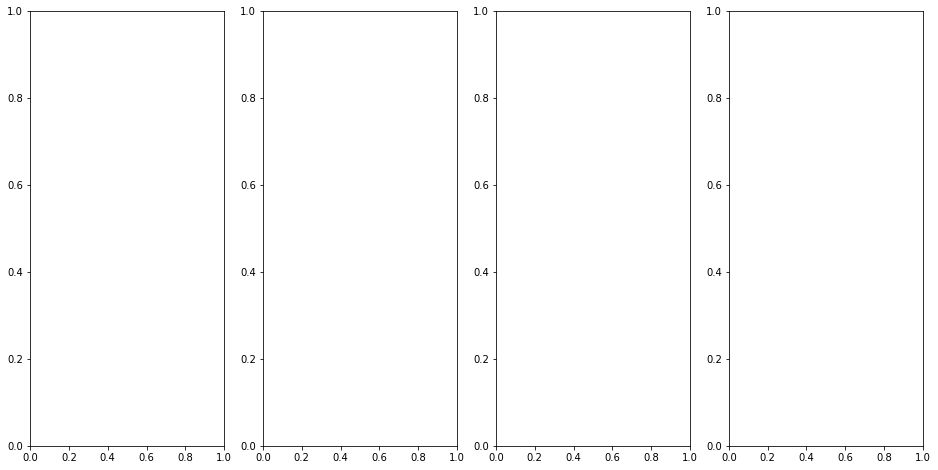

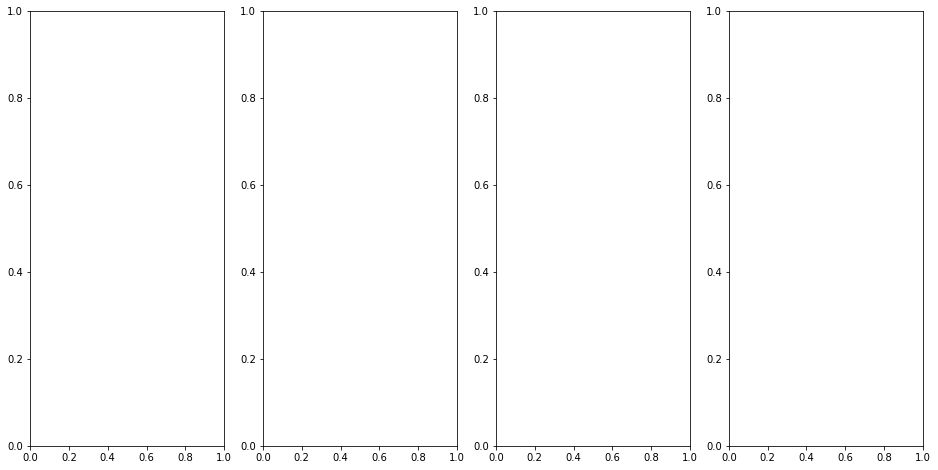

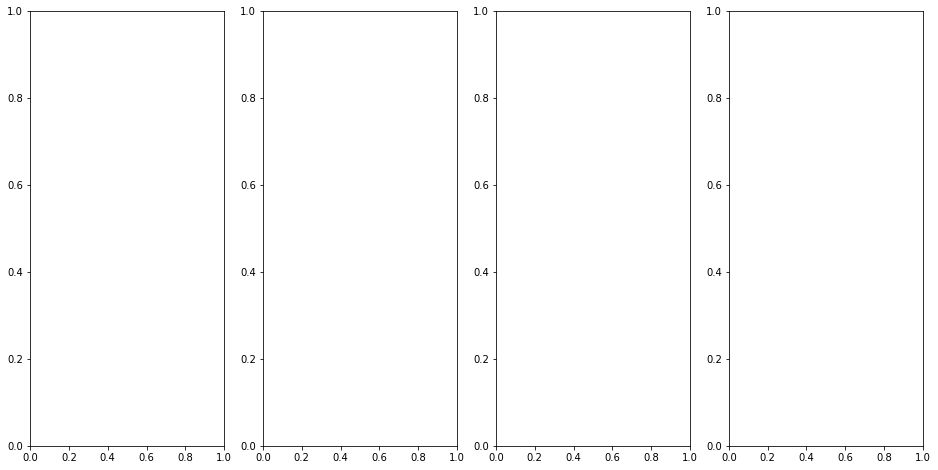

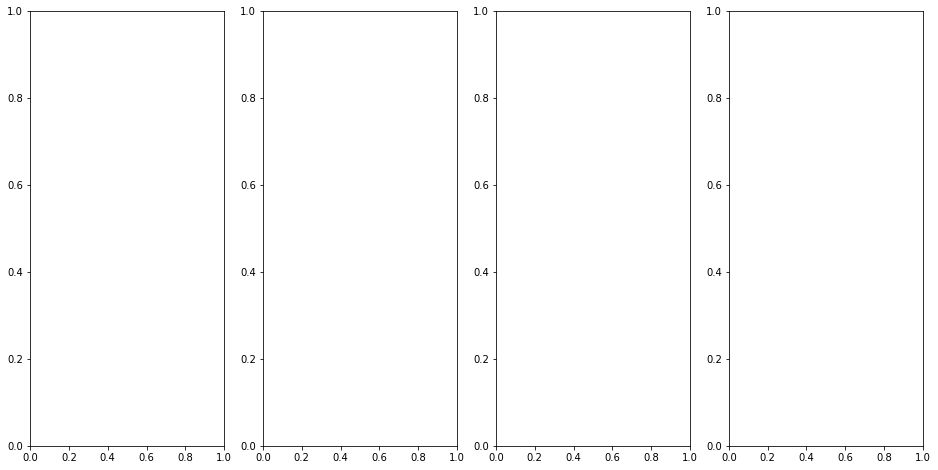

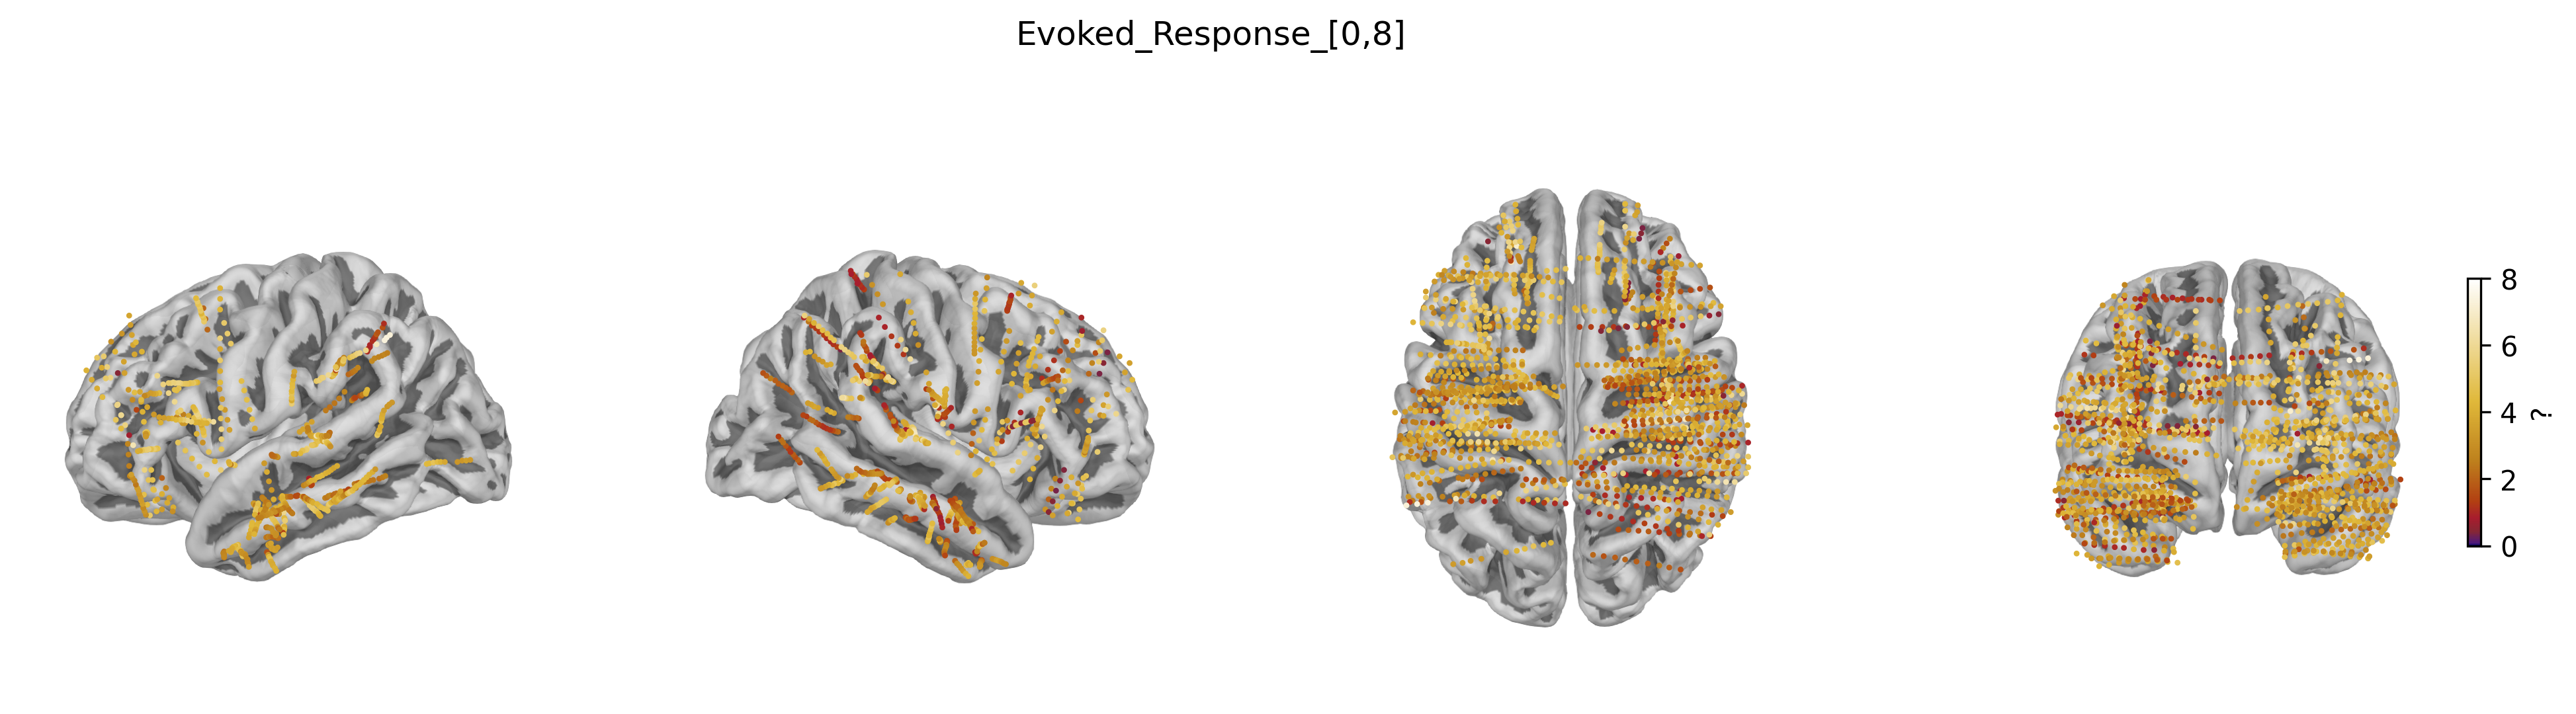

In [29]:
#plot
epochs_path = path + 'epochs_note_level/'
tw = [0, 8]

file_name = 'Evoked_Response_[' + str(tw[0]) + ',' + str(tw[1]) + ']'
scoring = '?'
vlim = [0,8]
thresh = 0
title = 'Evoked_Response_[' + str(tw[0]) + ',' + str(tw[1]) + ']'

scores = []
mask = []
for i_sub, sub in enumerate(sub_list):
    print('--', sub)
    ch_names = evoked_data[sub]['epochs'].ch_names
    tw_lim = [np.abs(times - tw[0]).argmin(), np.abs(times - tw[1]).argmin()+1]
    baseline_tw_lim = [np.abs(times - baseline_tw[0]).argmin(), np.abs(times - baseline_tw[1]).argmin()+1]

    #data shape : epochs, channels, times
    data_sub = data[i_sub]
    response = np.abs(data_sub[:,:,tw_lim[0]:tw_lim[1]])
    baseline = np.abs(data_sub[:,:,baseline_tw_lim[0]:baseline_tw_lim[1]]) #baseline mean has already been substracted from the stim period
    m_resp = np.mean(response, axis= 2) #average over time
    m_base = np.mean(baseline, axis = 2)
    s = np.mean(m_resp,axis=0) / np.std(m_base,axis=0)
    print(list(zip(list(s), ch_names)))
    # s = np.mean(data[i_sub][:,:,tw_lim[0]:tw_lim[1]],axis=(0,2)) / np.std(data[i_sub][:,:,baseline_tw_lim[0]:baseline_tw_lim[1]],axis=(0,2))
    # s = np.abs(s)
  
    scores.append(s)
    mask.append(s>thresh)

fig = plot_seeg(scores, scoring, mask, vlim, montages, title, fs_path, save_path + file_name + '.png', epochs_path, colormap = 'custom');